# Re-planning after a hold-up
The right arm is held up and both controllers re-plan from the state they reach: ours on the per-horizon program (compiled once per horizon, the imposed instances as parameters), Sound-LSE in CasADi with L-BFGS. The re-planning table on the planning model, the closed loop on the rigid-body simulation with the exact robustness of every until and reach instance on the executed motion, and the 64-cell circle's executed motion of the paper checked the same way. Updates and certificates beside the paper's (`results/`); the times are this machine's.

In [1]:
import os

os.environ["JAX_PLATFORMS"] = "cpu"
os.environ.update(OMP_NUM_THREADS="1", OPENBLAS_NUM_THREADS="1", MKL_NUM_THREADS="1")  # MUMPS and its BLAS on one thread, as the paper's solves ran
import jax
import matplotlib.pyplot as plt
import matplotlib_inline.backend_inline
import numpy as np

jax.config.update("jax_enable_x64", True)
from common import lse_loop, ours_loop, paper, paper_rows
from sparsemax_dstl.mpc import simulation as SIM
from sparsemax_dstl.tasks import dual_arm as D
from sparsemax_dstl.tasks import dual_arm_scenes as S
matplotlib_inline.backend_inline.set_matplotlib_formats("svg")

One row of the re-planning table: the eleven control periods from the first after the hold-up (14 samples from sample 113 at 100 time steps, 16 samples from sample 100 at 200), the state advanced by the plan's first accelerations on the planning model. The paper's row is the ten periods after the first; ours is the whole control period, the baseline's the solve alone and with the construction of its program.

In [2]:
def replan(T, P):
    delay, k0 = (14, 113) if T == 100 else (16, 100)
    every = ", a new plan every " + str(P) + " samples"
    mo = dict(horizon=T, comparator="SparseMax (ours)", variant="supports' structure, one program per horizon" + every)
    mb = dict(horizon=T, comparator="Sound-LSE", variant="L-BFGS" + every)
    ours, _ = ours_loop(delay, k0, T, 10, P)
    base = lse_loop(delay, k0, T, 10, P)
    print("horizon", T, "time steps, a new plan every", P, "samples")
    for name, out, m in (("ours", ours, mo), ("Sound-LSE", base, mb)):
        ref = [int(v) for v in paper_rows("replanning", quantity="updates", **m)[0]["values"].split(";")]
        print("  ", name, "updates", [s["updates"] for s in out[1:]], "| paper", ref, "| equal", [s["updates"] for s in out[1:]] == ref)
    print("   medians (s): ours", round(float(np.median([s["seconds"] for s in ours[1:]])), 3), "| paper", round(paper("replanning", quantity="whole control period", **mo), 3),
          "| Sound-LSE", round(float(np.median([s["seconds"] for s in base[1:]])), 3), "| paper", round(paper("replanning", quantity="solve time", **mb), 3),
          "| with construction", round(float(np.median([s["with_construction"] for s in base[1:]])), 3), "| paper", round(paper("replanning", quantity="solve and construction time", **mb), 3))

In [3]:
replan(100, 25)


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************



horizon 100 time steps, a new plan every 25 samples
   ours updates [4, 7, 10, 12, 6, 6, 5, 5, 5, 8] | paper [4, 7, 10, 12, 6, 6, 5, 5, 5, 8] | equal True
   Sound-LSE updates [46, 48, 73, 104, 91, 71, 53, 66, 59, 77] | paper [46, 48, 73, 104, 91, 71, 53, 66, 59, 77] | equal True
   medians (s): ours 0.11 | paper 0.159 | Sound-LSE 0.716 | paper 0.68 | with construction 3.286 | paper 4.153


In [4]:
replan(200, 25)

horizon 200 time steps, a new plan every 25 samples
   ours updates [18, 7, 6, 5, 8, 15, 35, 6, 6, 6] | paper [18, 7, 6, 5, 8, 15, 35, 6, 6, 6] | equal True
   Sound-LSE updates [256, 175, 191, 239, 167, 135, 215, 182, 246, 181] | paper [256, 175, 191, 239, 167, 135, 215, 182, 246, 181] | equal True
   medians (s): ours 0.297 | paper 0.361 | Sound-LSE 6.054 | paper 5.989 | with construction 13.808 | paper 14.638


In [5]:
replan(100, 1)

horizon 100 time steps, a new plan every 1 samples
   ours updates [7, 5, 5, 5, 5, 4, 4, 4, 4, 4] | paper [7, 5, 5, 5, 5, 4, 4, 4, 4, 4] | equal True
   Sound-LSE updates [76, 73, 82, 71, 61, 80, 55, 54, 74, 65] | paper [76, 73, 82, 71, 61, 80, 55, 54, 74, 65] | equal True
   medians (s): ours 0.114 | paper 0.141 | Sound-LSE 1.032 | paper 0.981 | with construction 5.597 | paper 6.412


In [6]:
replan(200, 1)

horizon 200 time steps, a new plan every 1 samples
   ours updates [5, 4, 4, 7, 3, 6, 3, 3, 3, 6] | paper [5, 4, 4, 7, 3, 6, 3, 3, 3, 6] | equal True
   Sound-LSE updates [139, 132, 135, 148, 124, 158, 112, 115, 126, 114] | paper [139, 132, 135, 148, 124, 158, 112, 115, 126, 114] | equal True
   medians (s): ours 0.202 | paper 0.238 | Sound-LSE 4.075 | paper 4.176 | with construction 11.559 | paper 13.056


The closed loop: a hold-up of 14 samples, the controllers from sample 100 at 100 time steps, a new plan every 25 samples for 21 control periods, each plan's first 25 joint positions held as targets by the joint drives of the rigid-body simulation.

In [7]:
ours, X = ours_loop(14, 100, 100, 20, 25, simulate=True)
base = lse_loop(14, 100, 100, 20, 25, simulate=True)
for name, out, comp, q in (("ours", ours, "SparseMax (ours)", "whole control period"), ("Sound-LSE", base, "Sound-LSE", "solve time")):
    rows = sorted(paper_rows("closed_loop", comparator=comp, quantity="updates", run=1), key=lambda r: int(r["period"]))
    ref = [int(r["value"]) for r in rows]
    t = [float(r["value"]) for r in paper_rows("closed_loop", comparator=comp, quantity=q) if r["period"] != "0"]
    s = [o["seconds"] for o in out[1:]]
    print(name, "updates", [o["updates"] for o in out], "| equal to the paper's", [o["updates"] for o in out] == ref)
    print("   periods after the first (s): smallest", round(min(s), 3), "largest", round(max(s), 3), "| paper, six runs:", round(min(t), 3), "to", round(max(t), 3))

ours updates [25, 5, 5, 5, 6, 10, 5, 5, 5, 4, 5, 12, 8, 5, 5, 5, 5, 12, 7, 6, 5] | equal to the paper's True
   periods after the first (s): smallest 0.062 largest 0.397 | paper, six runs: 0.089 to 0.469
Sound-LSE updates [101, 60, 79, 59, 106, 104, 78, 90, 67, 53, 54, 96, 89, 82, 58, 73, 55, 112, 81, 83, 78] | equal to the paper's True
   periods after the first (s): smallest 0.522 largest 1.465 | paper, six runs: 0.49 to 1.452


This machine's time of every control period after the first, with the control period of 0.5 s; saved as `out/closed-loop-times` (SVG and PDF).

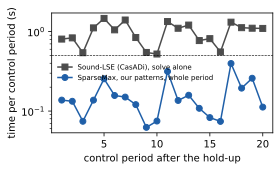

In [8]:
os.makedirs("out", exist_ok=True)
fig, ax = plt.subplots(figsize=(4, 2.4))
k = np.arange(1, 21)
ax.plot(k, [o["seconds"] for o in base[1:]], "s-", color="0.3", label="Sound-LSE (CasADi), solve alone")
ax.plot(k, [o["seconds"] for o in ours[1:]], "o-", color="#1f5fa8", label="SparseMax, our patterns, whole period")
ax.axhline(0.5, color="black", lw=0.6, ls="--")
ax.set_yscale("log")
ax.set_xlabel("control period after the hold-up")
ax.set_ylabel("time per control period (s)")
ax.legend(fontsize=7, frameon=False)
fig.tight_layout()
for ext in ("svg", "pdf"):
    fig.savefig("out/closed-loop-times." + ext, metadata={"Creator": None, "Date": None} if ext == "svg" else {"Creator": None, "Producer": None, "CreationDate": None})

The certificate of the executed motion (the executed states from sample 100 to 625, then the last plan's remainder): the exact robustness of every until and reach instance that ends in the run and is decided by it (its value differs from that on the plan that ignores the hold-up), and the smallest distance between the arms' collision spheres after the first period. Beside the exact predicates, the outside predicates with the length smoothing of the paper's record (0.5 mm), which gives the paper's values.

In [9]:
def certificate(scene, plan_scene, k0, last, length=0.0):
    run = SIM.instances(scene, length)
    plan = {(i["conjunct"], i["anchor"]): i["exact"] for i in SIM.instances(plan_scene, length)}
    for kind in ("until", "reach"):
        v = [(i["exact"], plan[i["conjunct"], i["anchor"]]) for i in run if i["kind"] == kind and k0 < i["last"] <= last and abs(i["exact"] - plan[i["conjunct"], i["anchor"]]) > 1e-12]
        print("  ", kind, "instances", len(v), "smallest", round(min(a for a, _ in v), 4), "on the plan that ignores the hold-up", round(min(b for _, b in v), 4),
              "below the margin 0.02", sum(a < 0.02 for a, _ in v))


def paper_certificate(scene):
    m = dict(scene=scene, comparator="SparseMax (ours)")
    for kind in ("until", "reach"):
        print("   paper", kind, "instances", int(paper("closed_loop", quantity=kind + " instances decided in the run", **m)), "smallest",
              round(paper("closed_loop", quantity="smallest exact robustness of the " + kind + " instances", **m), 4), "on the plan that ignores the hold-up",
              round(paper("closed_loop", quantity="smallest exact robustness of the " + kind + " instances on the plan that ignores the hold-up", **m), 4))
    print("   paper clearance (m)", round(paper("closed_loop", quantity="smallest distance between the arms' collision spheres after the first period", **m), 4))

In [10]:
print("exact predicates")
certificate(S.hold_up(100, 14, states=X), S.hold_up(100, 14), 100, 625)
print("outside predicates smoothed over 0.5 mm")
certificate(S.hold_up(100, 14, states=X), S.hold_up(100, 14), 100, 625, D.EPS_LENGTH)
print("   clearance (m)", round(float(SIM.clearance(X[100:626])[1:].min()), 4))
paper_certificate("five-cell zone")

exact predicates


   until instances 33 smallest 0.2963 on the plan that ignores the hold-up -0.3904 below the margin 0.02 0
   reach instances 21 smallest 0.3073 on the plan that ignores the hold-up 0.4179 below the margin 0.02 0
outside predicates smoothed over 0.5 mm


   until instances 33 smallest 0.2797 on the plan that ignores the hold-up -0.407 below the margin 0.02 0
   reach instances 21 smallest 0.3073 on the plan that ignores the hold-up 0.4179 below the margin 0.02 0


   clearance (m) 0.0382
   paper until instances 33 smallest 0.2797 on the plan that ignores the hold-up -0.407
   paper reach instances 21 smallest 0.3073 on the plan that ignores the hold-up 0.4179
   paper clearance (m) 0.0382


The 64-cell circle's executed motion of the paper (`data/circle_executed_motion.npz`: a hold-up of 38 samples, our controller from sample 164 with the structure widened by 2 samples, 13 control periods of 25 samples on the rigid-body simulation) checked with the same certificate; the circle's record used the exact predicates.

In [11]:
z = np.load("data/circle_executed_motion.npz")
delay, k0, P = int(z["delay"]), int(z["first_period"]), int(z["samples_per_period"])
last = k0 + int(z["periods"]) * P
certificate(S.circle(100, delay=delay, states=z["record"]), S.circle(100, delay=delay), k0, last)
print("   clearance (m)", round(float(SIM.clearance(z["record"][k0:last + 1])[1:].min()), 4))
paper_certificate("64-cell circle")

   until instances 225 smallest 0.2498 on the plan that ignores the hold-up -0.2196 below the margin 0.02 0
   reach instances 15 smallest 0.697 on the plan that ignores the hold-up 0.861 below the margin 0.02 0
   clearance (m) 0.0359


   paper until instances 225 smallest 0.2498 on the plan that ignores the hold-up -0.2196
   paper reach instances 15 smallest 0.697 on the plan that ignores the hold-up 0.861
   paper clearance (m) 0.0359
